| Field          | Detail                                      |
|----------------|---------------------------------------------|
| Analyst        | Pharm Chukwuma U. Emeka                               
| Date           | 25th October, 2026                                      
| Data Source    | NHS England Referral To Treatment Waiting Times         
| Python Version | 3.x                 
| Purpose        | Operational analysis of NHS England RTT Waiting 
|                | Times accross different Trusts and Specialties    
                   between September 2025 to August 2026
---
|Key variables:   period, provider_org_code, provider_org_name,
                  commissioner_org_code, commissioner_org_name,
                  treatment_function_code, treatment_function_name,
                  total_all,week_columns.


In [1]:
#Library Import
import pandas as pd                    
import numpy as np                     
import matplotlib.pyplot as plt        
import matplotlib.ticker as mticker    
import seaborn as sns               
import warnings
warnings.filterwarnings('ignore')
import os


CELL 2 BELOW DEFINES THE DATAFRAME SETTINGS WITH PANDAS SET-OPTION

In [2]:
#dataframe settings
pd.set_option('display.float_format',' {:,.1f}'.format)
pd.set_option('display.max_colwidth',60)

CELL 3 below involves the importation of the raw data from NHS RTT September 2025 extract
as a CSV file into python for initial data inspection

In [3]:


raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)

# ── Initial dataset inspection ────────────────────────────────────────
print('=' * 55)
print('NHS RTT WAITING DATASET — INITIAL INSPECTION')
print('=' * 55)
df=raw.copy()
print(f'Rows:    {df.shape[0]:,}')
print(f'Columns: {df.shape[1]}')
print()
print('Column names:')
print(df.columns.tolist())
print()
print('Data types:')
print(df.dtypes)
print()
print('First 5 rows:')

df.head()



NHS RTT WAITING DATASET — INITIAL INSPECTION
Rows:    184,484
Columns: 121

Column names:
['Period', 'Provider Parent Org Code', 'Provider Parent Name', 'Provider Org Code', 'Provider Org Name', 'Commissioner Parent Org Code', 'Commissioner Parent Name', 'Commissioner Org Code', 'Commissioner Org Name', 'RTT Part Type', 'RTT Part Description', 'Treatment Function Code', 'Treatment Function Name', 'Gt 00 To 01 Weeks SUM 1', 'Gt 01 To 02 Weeks SUM 1', 'Gt 02 To 03 Weeks SUM 1', 'Gt 03 To 04 Weeks SUM 1', 'Gt 04 To 05 Weeks SUM 1', 'Gt 05 To 06 Weeks SUM 1', 'Gt 06 To 07 Weeks SUM 1', 'Gt 07 To 08 Weeks SUM 1', 'Gt 08 To 09 Weeks SUM 1', 'Gt 09 To 10 Weeks SUM 1', 'Gt 10 To 11 Weeks SUM 1', 'Gt 11 To 12 Weeks SUM 1', 'Gt 12 To 13 Weeks SUM 1', 'Gt 13 To 14 Weeks SUM 1', 'Gt 14 To 15 Weeks SUM 1', 'Gt 15 To 16 Weeks SUM 1', 'Gt 16 To 17 Weeks SUM 1', 'Gt 17 To 18 Weeks SUM 1', 'Gt 18 To 19 Weeks SUM 1', 'Gt 19 To 20 Weeks SUM 1', 'Gt 20 To 21 Weeks SUM 1', 'Gt 21 To 22 Weeks SUM 1', 'Gt 22

,Period,Provider Parent Org Code,Provider Parent Name,Provider Org Code,Provider Org Name,Commissioner Parent Org Code,Commissioner Parent Name,Commissioner Org Code,Commissioner Org Name,RTT Part Type,...,Gt 98 To 99 Weeks SUM 1,Gt 99 To 100 Weeks SUM 1,Gt 100 To 101 Weeks SUM 1,Gt 101 To 102 Weeks SUM 1,Gt 102 To 103 Weeks SUM 1,Gt 103 To 104 Weeks SUM 1,Gt 104 Weeks SUM 1,Total,Patients with unknown clock start date,Total All
0,RTT-September-2025,QE1,NHS LANCASHIRE AND SOUTH CUMBRIA INTEGRATED CARE BOARD,A4M8P,BUCKSHAW HOSPITAL,NaN,NaN,13Q,NATIONAL COMMISSIONING HUB 1,Part_2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,1
1,RTT-September-2025,QE1,NHS LANCASHIRE AND SOUTH CUMBRIA INTEGRATED CARE BOARD,A4M8P,BUCKSHAW HOSPITAL,NaN,NaN,13Q,NATIONAL COMMISSIONING HUB 1,Part_2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,1
2,RTT-September-2025,QE1,NHS LANCASHIRE AND SOUTH CUMBRIA INTEGRATED CARE BOARD,A4M8P,BUCKSHAW HOSPITAL,NaN,NaN,Y62,NaN,Part_2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,3
3,RTT-September-2025,QE1,NHS LANCASHIRE AND SOUTH CUMBRIA INTEGRATED CARE BOARD,A4M8P,BUCKSHAW HOSPITAL,NaN,NaN,Y62,NaN,Part_2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,3
4,RTT-September-2025,QE1,NHS LANCASHIRE AND SOUTH CUMBRIA INTEGRATED CARE BOARD,A4M8P,BUCKSHAW HOSPITAL,NaN,NaN,Y62,NaN,Part_2A,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,2


CELL 4 below begins the dataset cleaning process.
1. First step is a standardization of all columns to lower cases, removal of empty spaces
   between text etc

In [4]:
#DATA CLEANING PROCESS
# 1) Standardize column names
df.columns = (df.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df.columns.tolist())


['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

CELL 5 below removes whitespaces before and after text values in columns with object 
data types

In [5]:
# 2)Strip whitespaces from text values
text_cols = df.select_dtypes("object").columns
for c in text_cols:
    df[c] = df[c].str.strip()


CELL 6 below fixes the data type in the 'period' column from 'object' to 'datetime'
And also enforces that week columns remain numeric all through

In [6]:
# 3) fix data types
# "RTT-September-2025" -> real date
df["period"] = pd.to_datetime(df["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric. Bands already numeric from raw data, but the coerce is enforced for other months
week_cols = [c for c in df.columns if c.startswith("gt_")]
df[week_cols] = df[week_cols].apply(pd.to_numeric, errors="coerce")
print(df.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
                                               ...      
gt_103_to_104_weeks_sum_1                        float64
gt_104_weeks_sum_1                               float64
total                                            float64
patients_with_unknown_clock_start_date           float64
total_all                                          int64
Length: 121, dtype: object


CELL 7 below checks for missing values across columns, and prints out only columns with greater than 0 missing values

In [7]:
# 4) Investigate missing values
missing = df.isnull().sum()
print(missing[missing > 0])

# Are the blanks tied to particular pathway types?
print(df.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10620
commissioner_parent_name                   10620
commissioner_org_name                       3268
gt_00_to_01_weeks_sum_1                    51187
gt_01_to_02_weeks_sum_1                    51789
                                           ...  
gt_102_to_103_weeks_sum_1                  60383
gt_103_to_104_weeks_sum_1                  60274
gt_104_weeks_sum_1                         58717
total                                     132625
patients_with_unknown_clock_start_date    150490
Length: 110, dtype: int64
rtt_part_type
Part_1A     11.9
Part_1B     13.3
Part_2      13.2
Part_2A     12.6
Part_3     100.0
dtype: float64


CELL 8 fills blank spaces in some columns with structural defects

In [8]:
# 5) blank commissioner names replaced with not-recorded; a structural defect
df["commissioner_org_name"] = df["commissioner_org_name"].fillna("Not recorded")


CELL 9 checks for duplicate rows and removes any duplicated row across the dataset

In [9]:
# 6) Check for duplicate rows and Remove duplicate rows
duplicate_rows = df.duplicated().sum()
print("Duplicates:", duplicate_rows)
df = df.drop_duplicates()


Duplicates: 0


CELL 9 checks for plausibility by confirming the absence of any negative patient in the weeks columns

In [10]:
# 7) checking ranges...plausible ranges to check for negative patients in weeks columns
neg = (df[week_cols] < 0).sum().sum()
print("Negative counts:", neg)


Negative counts: 0


CELL 11 below checks the totals and total-all columns of the part-2 pathway for reconciliation of missing values and week-band

In [11]:
#cross checking the totals and total-all columns for the part-2 pathway:
#missing values and week-band reconciliation
print([c for c in df.columns if "total" in c])

incomplete_pathway = df[df["rtt_part_type"] == "Part_2"]
print(incomplete_pathway[["total", "total_all"]].isnull().mean() * 100)

# Proper check: flag NaN totals as well as mismatches
band_sum = incomplete_pathway[week_cols].sum(axis=1)
mismatch = (incomplete_pathway["total_all"].isnull()) | ((incomplete_pathway["total_all"] - band_sum).abs() > 0)
print("Rows failing:", mismatch.sum(), "of", len(incomplete_pathway))

['total', 'total_all']
total        100.0
total_all      0.0
dtype: float64
Rows failing: 0 of 64994


CELL 12 below checks each column label for consistency

In [12]:
#Check labels for constistency to ensure text categories are clean
print(df["treatment_function_name"].value_counts())
print(df["provider_org_name"].nunique(), "trust names |",
         df["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                40587
Trauma and Orthopaedic Service       15968
Ophthalmology Service                12266
Other - Medical Services             10208
General Surgery Service               9292
Gynaecology Service                   9193
Urology Service                       9133
Ear Nose and Throat Service           8872
Other - Surgical Services             8549
Gastroenterology Service              7239
Oral Surgery Service                  7145
Cardiology Service                    6457
Other - Paediatric Services           6005
Dermatology Service                   5113
Other - Other Services                5022
Respiratory Medicine Service          4470
Plastic Surgery Service               4464
Neurology Service                     3947
Rheumatology Service                  3390
Neurosurgical Service                 2322
General Internal Medicine Service     1779
Elderly Medicine Service              1419
Cardiothoracic Surgery Service

CELL 15 is a follow up on cell 14, with discrepancy in trust code and trust name
the cell below highlights the discrepancy using the groupby function

In [13]:
#Trust names 476 vs Trust code 477. One name has two different codes

names = df.groupby("provider_org_name")["provider_org_code"].nunique()
dup_name = names[names > 1]
print(dup_name)

df[df["provider_org_name"].isin(dup_name.index)][
    ["provider_org_code", "provider_org_name"]].drop_duplicates()

provider_org_name
DUCHY HOSPITAL    2
Name: provider_org_code, dtype: int64


,provider_org_code,provider_org_name
99490,NT447,DUCHY HOSPITAL
130444,NVC04,DUCHY HOSPITAL


CELL 16 confirms the findings of 14 and 15. Two different hospitals in different ICBs 
bear the same name. Therefore to avoid duplicate counting, unique provider codes are used instead of provider names

In [14]:
#checking the parents and patient numbers...two different hospitals sharing same name
df[df["provider_org_code"].isin(["NT447", "NVC04"])].groupby(
    ["provider_org_code", "provider_parent_name"])["total"].sum()

provider_org_code  provider_parent_name                                      
NT447              NHS HUMBER AND NORTH YORKSHIRE INTEGRATED CARE BOARD          212.0
NVC04              NHS CORNWALL AND THE ISLES OF SCILLY INTEGRATED CARE BOARD    430.0
Name: total, dtype: float64

CELL 17 below saves the cleaned dataset, with exclusion of sub_totals in treatment_function_code,
and selection of the required colomns for analysis thereby reducing it to 113 columns

In [15]:
clean = df[(df["rtt_part_type"] == "Part_2") &
           (df["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(52067, 113)


CELL 18 saves the cleaned data as csv document in a created RTT_data folder

In [16]:
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

CELL 19 is the missing values chart

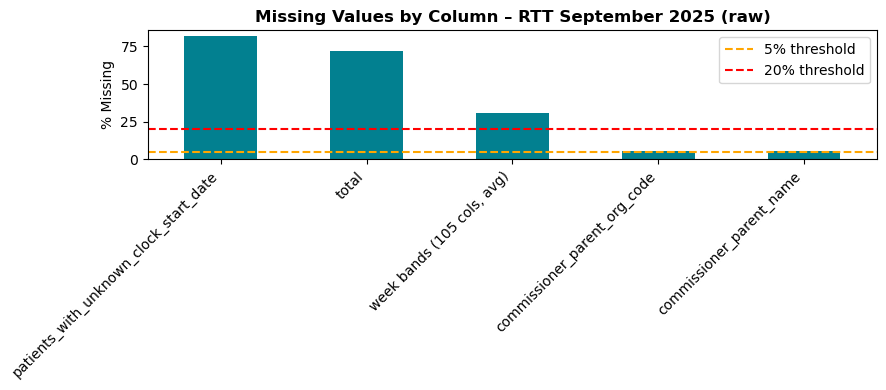

In [17]:
#missing values chart
import matplotlib.pyplot as plt

raw_cols = df.columns  # df has standardised names but its original missing values
missing_pct = (df.isnull().mean() * 100)

week_cols = [c for c in df.columns if c.startswith("gt_")]
summary = missing_pct.drop(week_cols)
summary["week bands (105 cols, avg)"] = missing_pct[week_cols].mean()
summary = summary[summary > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
summary.plot(kind="bar", color="#028090", ax=ax)
ax.set_ylabel("% Missing")
ax.set_title("Missing Values by Column – RTT September 2025 (raw)", fontweight="bold")
ax.axhline(5, color="orange", ls="--", label="5% threshold")
ax.axhline(20, color="red", ls="--", label="20% threshold")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("DQ_Missing_Values.png", dpi=150)
plt.show()

CELL 18 below saves the cleaned data for September 2025 as csv file

In [18]:
sep_clean= clean.copy()
sep_clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)
print(sep_clean.shape, sep_clean.columns[:8].tolist())

(52067, 113) ['period', 'provider_org_code', 'provider_org_name', 'commissioner_org_code', 'commissioner_org_name', 'treatment_function_code', 'treatment_function_name', 'total_all']


FROM CELL 19 DOWNWARDS, 
The entire cleaning process was repeated from October 2025 through August 2026, 
each step beginning with the importation of the RTT full extracts into Python

In [19]:
##OCTOBER 2025

In [20]:
raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_oct = raw.copy()          
                
print(df_oct.shape)

(185742, 121)


In [21]:
#Standardize column names
df_oct.columns = (df_oct.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_oct.columns.tolist())


['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [22]:
#Strip whitespaces from text values
text_cols = df_oct.select_dtypes("object").columns
for c in text_cols:
    df_oct[c] = df_oct[c].str.strip()

In [23]:
#check datatypes
print(df_oct.dtypes)

period                                     object
provider_parent_org_code                   object
provider_parent_name                       object
provider_org_code                          object
provider_org_name                          object
                                           ...   
gt_103_to_104_weeks_sum_1                 float64
gt_104_weeks_sum_1                        float64
total                                     float64
patients_with_unknown_clock_start_date    float64
total_all                                   int64
Length: 121, dtype: object


In [24]:
pd.set_option("display.max_rows", None)
print(df_oct.dtypes)

period                                     object
provider_parent_org_code                   object
provider_parent_name                       object
provider_org_code                          object
provider_org_name                          object
commissioner_parent_org_code               object
commissioner_parent_name                   object
commissioner_org_code                      object
commissioner_org_name                      object
rtt_part_type                              object
rtt_part_description                       object
treatment_function_code                    object
treatment_function_name                    object
gt_00_to_01_weeks_sum_1                   float64
gt_01_to_02_weeks_sum_1                   float64
gt_02_to_03_weeks_sum_1                   float64
gt_03_to_04_weeks_sum_1                   float64
gt_04_to_05_weeks_sum_1                   float64
gt_05_to_06_weeks_sum_1                   float64
gt_06_to_07_weeks_sum_1                   float64


In [25]:
#fix data types
# "RTT-October-2025" -> real date
df_oct["period"] = pd.to_datetime(df_oct["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_oct.columns if c.startswith("gt_")]
df_oct[week_cols] = df_oct[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_oct.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [26]:
#How many columns of each type
print(df_oct.dtypes.value_counts())

float64           107
object             12
datetime64[ns]      1
int64               1
Name: count, dtype: int64


In [27]:
#Investigate missing values
missing = df_oct.isnull().sum()
print(missing[missing > 0])

# Are the blanks tied to particular pathway types?
print(df_oct.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10736
commissioner_parent_name                   10736
commissioner_org_name                       3327
gt_00_to_01_weeks_sum_1                    52044
gt_01_to_02_weeks_sum_1                    52429
gt_02_to_03_weeks_sum_1                    52497
gt_03_to_04_weeks_sum_1                    52598
gt_04_to_05_weeks_sum_1                    52617
gt_05_to_06_weeks_sum_1                    52921
gt_06_to_07_weeks_sum_1                    53071
gt_07_to_08_weeks_sum_1                    53230
gt_08_to_09_weeks_sum_1                    53327
gt_09_to_10_weeks_sum_1                    53854
gt_10_to_11_weeks_sum_1                    53632
gt_11_to_12_weeks_sum_1                    53775
gt_12_to_13_weeks_sum_1                    53806
gt_13_to_14_weeks_sum_1                    53893
gt_14_to_15_weeks_sum_1                    53944
gt_15_to_16_weeks_sum_1                    54017
gt_16_to_17_weeks_sum_1                    54109
gt_17_to_18_weeks_su

In [28]:
#blank commissioner names replaced with not-recorded; a structural defect
df_oct["commissioner_org_name"] = df_oct["commissioner_org_name"].fillna("Not recorded")


In [29]:
#Remove duplicate rows
duplicate_rows = df_oct.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_oct = df_oct.drop_duplicates()


Duplicates: 0


In [30]:
#checking ranges...plausible ranges to check for negative patients
neg = (df_oct[week_cols] < 0).sum().sum()
print("Negative counts:", neg)


Negative counts: 0


In [31]:
inc = df_oct[df_oct["rtt_part_type"] == "Part_2"]
band_sum = inc[week_cols].sum(axis=1)
fail = inc["total_all"].isnull() | ((inc["total_all"] - band_sum).abs() > 0)
print("Failures:", fail.sum(), "of", len(inc))

Failures: 0 of 65332


In [32]:
#Check labels for constistency
print(df_oct["treatment_function_name"].value_counts())
print(df_oct["provider_org_name"].nunique(), "trust names |",
         df_oct["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                40903
Trauma and Orthopaedic Service       16050
Ophthalmology Service                12382
Other - Medical Services             10230
Gynaecology Service                   9366
General Surgery Service               9348
Urology Service                       9215
Ear Nose and Throat Service           8927
Other - Surgical Services             8518
Gastroenterology Service              7348
Oral Surgery Service                  7205
Cardiology Service                    6444
Other - Paediatric Services           6024
Other - Other Services                5146
Dermatology Service                   5124
Respiratory Medicine Service          4504
Plastic Surgery Service               4462
Neurology Service                     3990
Rheumatology Service                  3399
Neurosurgical Service                 2292
General Internal Medicine Service     1745
Elderly Medicine Service              1399
Cardiothoracic Surgery Service

In [33]:
#Trust names 476 vs Trust code 477
#check this and find which
names = df_oct.groupby("provider_org_name")["provider_org_code"].nunique()
dup_name = names[names > 1]
print(dup_name)

df_oct[df_oct["provider_org_name"].isin(dup_name.index)][
    ["provider_org_code", "provider_org_name"]].drop_duplicates()

provider_org_name
DUCHY HOSPITAL    2
Name: provider_org_code, dtype: int64


,provider_org_code,provider_org_name
100042,NT447,DUCHY HOSPITAL
131171,NVC04,DUCHY HOSPITAL


In [34]:
#checking the parents and patient numbers...two different hospitals sharing same name
df_oct[df_oct["provider_org_code"].isin(["NT447", "NVC04"])].groupby(
    ["provider_org_code", "provider_parent_name"])["total"].sum()

provider_org_code  provider_parent_name                                      
NT447              NHS HUMBER AND NORTH YORKSHIRE INTEGRATED CARE BOARD          272.0
NVC04              NHS CORNWALL AND THE ISLES OF SCILLY INTEGRATED CARE BOARD    492.0
Name: total, dtype: float64

In [35]:
clean = df_oct[(df_oct["rtt_part_type"] == "Part_2") &
           (df_oct["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(52322, 113)


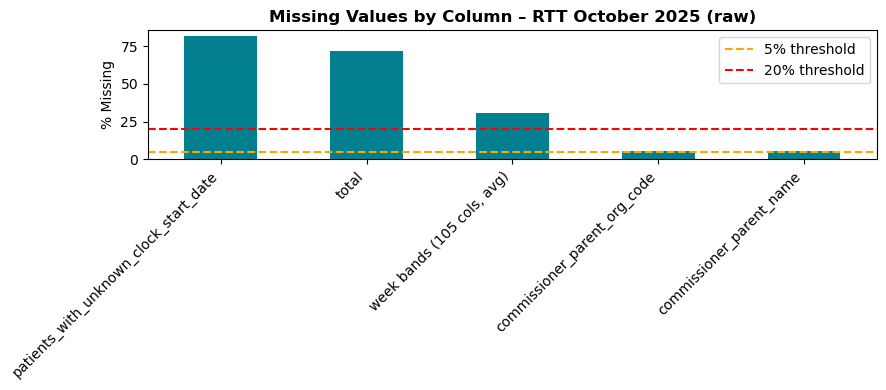

In [36]:
#missing values chart
import matplotlib.pyplot as plt

raw_cols = df_oct.columns  # df has standardised names but its original missing values
missing_pct = (df_oct.isnull().mean() * 100)

week_cols = [c for c in df_oct.columns if c.startswith("gt_")]
summary = missing_pct.drop(week_cols)
summary["week bands (105 cols, avg)"] = missing_pct[week_cols].mean()
summary = summary[summary > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
summary.plot(kind="bar", color="#028090", ax=ax)
ax.set_ylabel("% Missing")
ax.set_title("Missing Values by Column – RTT October 2025 (raw)", fontweight="bold")
ax.axhline(5, color="orange", ls="--", label="5% threshold")
ax.axhline(20, color="red", ls="--", label="20% threshold")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("DQ_Missing_Values.png", dpi=150)
plt.show()

In [37]:
#Save october cleaned
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

In [38]:
del raw,df_oct,inc,clean

In [39]:
#NOVEMBER

In [40]:
raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_nov = raw.copy()          
                
print(df_nov.shape)

(180291, 121)


In [41]:
#check datatypes
print(df_nov.dtypes)

Period                                     object
Provider Parent Org Code                   object
Provider Parent Name                       object
Provider Org Code                          object
Provider Org Name                          object
Commissioner Parent Org Code               object
Commissioner Parent Name                   object
Commissioner Org Code                      object
Commissioner Org Name                      object
RTT Part Type                              object
RTT Part Description                       object
Treatment Function Code                    object
Treatment Function Name                    object
Gt 00 To 01 Weeks SUM 1                   float64
Gt 01 To 02 Weeks SUM 1                   float64
Gt 02 To 03 Weeks SUM 1                   float64
Gt 03 To 04 Weeks SUM 1                   float64
Gt 04 To 05 Weeks SUM 1                   float64
Gt 05 To 06 Weeks SUM 1                   float64
Gt 06 To 07 Weeks SUM 1                   float64


In [42]:
#Standardize column names
df_nov.columns = (df_nov.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_nov.columns.tolist())


['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [43]:
#fix data types
# "RTT-November-2025" -> real date
df_nov["period"] = pd.to_datetime(df_nov["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_nov.columns if c.startswith("gt_")]
df_nov[week_cols] = df_nov[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_nov.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [44]:
#Strip whitespaces from text values
text_cols = df_nov.select_dtypes("object").columns
for c in text_cols:
    df_nov[c] = df_nov[c].str.strip()

In [45]:
#How many columns of each type
print(df_nov.dtypes.value_counts())

float64           107
object             12
datetime64[ns]      1
int64               1
Name: count, dtype: int64


In [46]:
#Investigate missing values
missing = df_nov.isnull().sum()
print(missing[missing > 0])

# Are the blanks tied to particular pathway types?
print(df_nov.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10347
commissioner_parent_name                   10347
commissioner_org_name                       3259
gt_00_to_01_weeks_sum_1                    49765
gt_01_to_02_weeks_sum_1                    49962
gt_02_to_03_weeks_sum_1                    49970
gt_03_to_04_weeks_sum_1                    50033
gt_04_to_05_weeks_sum_1                    50238
gt_05_to_06_weeks_sum_1                    50302
gt_06_to_07_weeks_sum_1                    50393
gt_07_to_08_weeks_sum_1                    50502
gt_08_to_09_weeks_sum_1                    50664
gt_09_to_10_weeks_sum_1                    50934
gt_10_to_11_weeks_sum_1                    50945
gt_11_to_12_weeks_sum_1                    51146
gt_12_to_13_weeks_sum_1                    51209
gt_13_to_14_weeks_sum_1                    51677
gt_14_to_15_weeks_sum_1                    51548
gt_15_to_16_weeks_sum_1                    51565
gt_16_to_17_weeks_sum_1                    51622
gt_17_to_18_weeks_su

In [47]:
#blank commissioner names replaced with not-recorded; a structural defect
df_nov["commissioner_org_name"] = df_nov["commissioner_org_name"].fillna("Not recorded")


In [48]:
#Remove duplicate rows
duplicate_rows = df_nov.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_nov = df_nov.drop_duplicates()


Duplicates: 0


In [49]:
#checking ranges...plausible ranges to check for negative patients
neg = (df_nov[week_cols] < 0).sum().sum()
print("Negative counts:", neg)


Negative counts: 0


In [50]:
#check rows by row for week band
inc = df_nov[df_nov["rtt_part_type"] == "Part_2"]
band_sum = inc[week_cols].sum(axis=1)
fail = inc["total_all"].isnull() | ((inc["total_all"] - band_sum).abs() > 0)
print("Failures:", fail.sum(), "of", len(inc))

Failures: 0 of 64526


In [51]:
#Check labels for constistency
print(df_nov["treatment_function_name"].value_counts())
print(df_nov["provider_org_name"].nunique(), "trust names |",
         df_nov["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                39764
Trauma and Orthopaedic Service       15482
Ophthalmology Service                12244
Other - Medical Services              9895
Gynaecology Service                   9107
General Surgery Service               9103
Urology Service                       8912
Ear Nose and Throat Service           8632
Other - Surgical Services             8363
Gastroenterology Service              7117
Oral Surgery Service                  6969
Cardiology Service                    6318
Other - Paediatric Services           5869
Dermatology Service                   4969
Other - Other Services                4804
Plastic Surgery Service               4356
Respiratory Medicine Service          4302
Neurology Service                     3834
Rheumatology Service                  3316
Neurosurgical Service                 2179
General Internal Medicine Service     1696
Elderly Medicine Service              1384
Cardiothoracic Surgery Service

In [52]:
#Trust names and codes inconsistency
#check this and find which
names = df_nov.groupby("provider_org_name")["provider_org_code"].nunique()
dup_name = names[names > 1]
print(dup_name)

df_nov[df_nov["provider_org_name"].isin(dup_name.index)][
    ["provider_org_code", "provider_org_name"]].drop_duplicates()

provider_org_name
DUCHY HOSPITAL    2
Name: provider_org_code, dtype: int64


,provider_org_code,provider_org_name
96304,NT447,DUCHY HOSPITAL
126621,NVC04,DUCHY HOSPITAL


In [53]:
#checking the parents and patient numbers...two different hospitals sharing same name
df_nov[df_nov["provider_org_code"].isin(["NT447", "NVC04"])].groupby(
    ["provider_org_code", "provider_parent_name"])["total"].sum()

provider_org_code  provider_parent_name                                      
NT447              NHS HUMBER AND NORTH YORKSHIRE INTEGRATED CARE BOARD          220.0
NVC04              NHS CORNWALL AND THE ISLES OF SCILLY INTEGRATED CARE BOARD    498.0
Name: total, dtype: float64

In [54]:
clean_nov = df_nov[(df_nov["rtt_part_type"] == "Part_2") &
           (df_nov["treatment_function_code"] != "C_999")].copy()

clean_nov[week_cols] = clean_nov[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean_nov = clean_nov[keep]
print(clean_nov.shape)

(51617, 113)


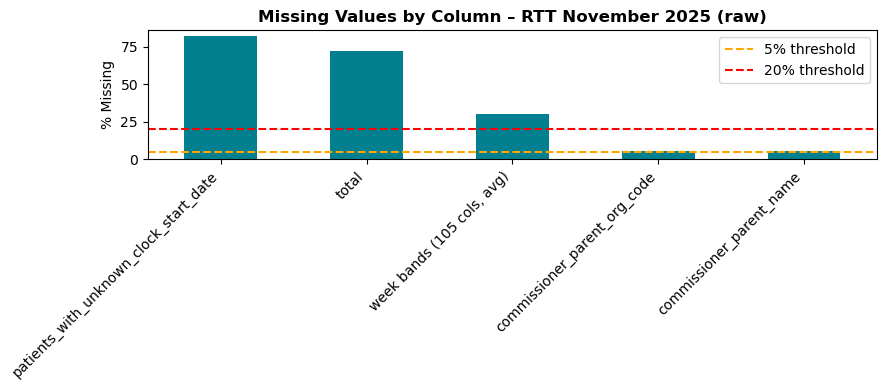

In [55]:
#missing values chart
import matplotlib.pyplot as plt

raw_cols = df_nov.columns  
missing_pct = (df_nov.isnull().mean() * 100)

week_cols = [c for c in df_nov.columns if c.startswith("gt_")]
summary = missing_pct.drop(week_cols)
summary["week bands (105 cols, avg)"] = missing_pct[week_cols].mean()
summary = summary[summary > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
summary.plot(kind="bar", color="#028090", ax=ax)
ax.set_ylabel("% Missing")
ax.set_title("Missing Values by Column – RTT November 2025 (raw)", fontweight="bold")
ax.axhline(5, color="orange", ls="--", label="5% threshold")
ax.axhline(20, color="red", ls="--", label="20% threshold")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("DQ_Missing_Values.png", dpi=150)
plt.show()

In [56]:
#Save November cleaned
clean_nov.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

In [57]:
import pandas as pd
import os

In [58]:
#DECEMBER
raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_dec = raw.copy()          
                
print(df_dec.shape)

(179823, 121)


In [59]:
#check datatypes
print(df_dec.dtypes)

Period                                     object
Provider Parent Org Code                   object
Provider Parent Name                       object
Provider Org Code                          object
Provider Org Name                          object
Commissioner Parent Org Code               object
Commissioner Parent Name                   object
Commissioner Org Code                      object
Commissioner Org Name                      object
RTT Part Type                              object
RTT Part Description                       object
Treatment Function Code                    object
Treatment Function Name                    object
Gt 00 To 01 Weeks SUM 1                   float64
Gt 01 To 02 Weeks SUM 1                   float64
Gt 02 To 03 Weeks SUM 1                   float64
Gt 03 To 04 Weeks SUM 1                   float64
Gt 04 To 05 Weeks SUM 1                   float64
Gt 05 To 06 Weeks SUM 1                   float64
Gt 06 To 07 Weeks SUM 1                   float64


In [60]:
#Standardize column names
df_dec.columns = (df_dec.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_dec.columns.tolist())


['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [61]:
#fix data types
# "RTT-December-2025" -> real date
df_dec["period"] = pd.to_datetime(df_dec["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_dec.columns if c.startswith("gt_")]
df_dec[week_cols] = df_dec[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_dec.dtypes)


period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [62]:
#Strip whitespaces from text values
text_cols = df_dec.select_dtypes("object").columns
for c in text_cols:
    df_dec[c] = df_dec[c].str.strip()

In [63]:
#How many columns of each type
print(df_dec.dtypes.value_counts())

float64           107
object             12
datetime64[ns]      1
int64               1
Name: count, dtype: int64


In [64]:
#Investigate missing values
missing = df_dec.isnull().sum()
print(missing[missing > 0])

# Are the blanks tied to particular pathway types?
print(df_dec.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10296
commissioner_parent_name                   10296
commissioner_org_name                       3311
gt_00_to_01_weeks_sum_1                    49772
gt_01_to_02_weeks_sum_1                    49609
gt_02_to_03_weeks_sum_1                    49553
gt_03_to_04_weeks_sum_1                    49628
gt_04_to_05_weeks_sum_1                    49634
gt_05_to_06_weeks_sum_1                    49799
gt_06_to_07_weeks_sum_1                    50008
gt_07_to_08_weeks_sum_1                    50141
gt_08_to_09_weeks_sum_1                    50317
gt_09_to_10_weeks_sum_1                    50460
gt_10_to_11_weeks_sum_1                    50555
gt_11_to_12_weeks_sum_1                    50552
gt_12_to_13_weeks_sum_1                    50676
gt_13_to_14_weeks_sum_1                    50892
gt_14_to_15_weeks_sum_1                    51007
gt_15_to_16_weeks_sum_1                    51093
gt_16_to_17_weeks_sum_1                    51191
gt_17_to_18_weeks_su

In [65]:
#blank commissioner names replaced with not-recorded; a structural defect
df_dec["commissioner_org_name"] = df_dec["commissioner_org_name"].fillna("Not recorded")

In [66]:
#Remove duplicate rows
duplicate_rows = df_dec.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_dec = df_dec.drop_duplicates()

Duplicates: 0


In [67]:
#checking ranges...plausible ranges to check for negative patients
neg = (df_dec[week_cols] < 0).sum().sum()
print("Negative counts:", neg)

Negative counts: 0


In [68]:
#check rows by row for week band
inc = df_dec[df_dec["rtt_part_type"] == "Part_2"]
band_sum = inc[week_cols].sum(axis=1)
fail = inc["total_all"].isnull() | ((inc["total_all"] - band_sum).abs() > 0)
print("Failures:", fail.sum(), "of", len(inc))

Failures: 0 of 65174


In [69]:
#Check labels for constistency
print(df_dec["treatment_function_name"].value_counts())
print(df_dec["provider_org_name"].nunique(), "trust names |",
         df_dec["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                39558
Trauma and Orthopaedic Service       15299
Ophthalmology Service                12036
Other - Medical Services              9838
Gynaecology Service                   9212
General Surgery Service               9038
Urology Service                       8888
Other - Surgical Services             8620
Ear Nose and Throat Service           8576
Gastroenterology Service              7129
Oral Surgery Service                  6998
Cardiology Service                    6300
Other - Paediatric Services           5800
Dermatology Service                   4946
Other - Other Services                4946
Respiratory Medicine Service          4326
Plastic Surgery Service               4266
Neurology Service                     3905
Rheumatology Service                  3237
Neurosurgical Service                 2274
General Internal Medicine Service     1695
Elderly Medicine Service              1355
Cardiothoracic Surgery Service

In [70]:
#Trust names and codes inconsistency
#check this and find which
names = df_dec.groupby("provider_org_name")["provider_org_code"].nunique()
dup_name = names[names > 1]
print(dup_name)

df_dec[df_dec["provider_org_name"].isin(dup_name.index)][
    ["provider_org_code", "provider_org_name"]].drop_duplicates()

provider_org_name
DUCHY HOSPITAL    2
Name: provider_org_code, dtype: int64


,provider_org_code,provider_org_name
97039,NT447,DUCHY HOSPITAL
127434,NVC04,DUCHY HOSPITAL


In [71]:
#checking the parents and patient numbers...two different hospitals sharing same name
df_dec[df_dec["provider_org_code"].isin(["NT447", "NVC04"])].groupby(
    ["provider_org_code", "provider_parent_name"])["total"].sum()

provider_org_code  provider_parent_name                                      
NT447              NHS HUMBER AND NORTH YORKSHIRE INTEGRATED CARE BOARD          172.0
NVC04              NHS CORNWALL AND THE ISLES OF SCILLY INTEGRATED CARE BOARD    382.0
Name: total, dtype: float64

In [72]:
clean = df_dec[(df_dec["rtt_part_type"] == "Part_2") &
           (df_dec["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(52217, 113)


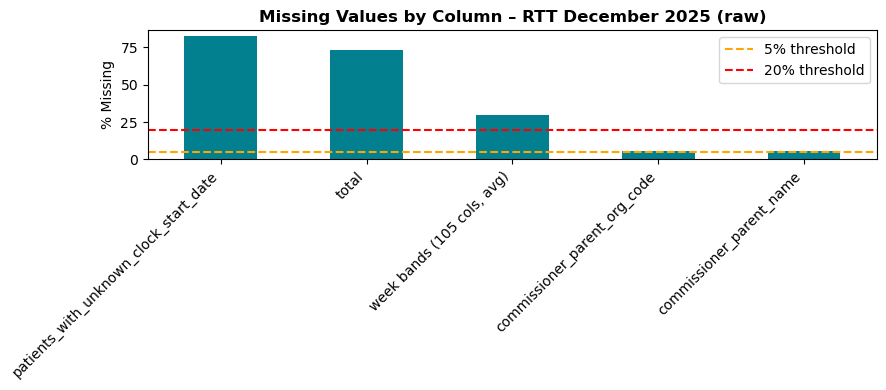

In [73]:
#missing values chart
import matplotlib.pyplot as plt

raw_cols = df_dec.columns  
missing_pct = (df_dec.isnull().mean() * 100)

week_cols = [c for c in df_dec.columns if c.startswith("gt_")]
summary = missing_pct.drop(week_cols)
summary["week bands (105 cols, avg)"] = missing_pct[week_cols].mean()
summary = summary[summary > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
summary.plot(kind="bar", color="#028090", ax=ax)
ax.set_ylabel("% Missing")
ax.set_title("Missing Values by Column – RTT December 2025 (raw)", fontweight="bold")
ax.axhline(5, color="orange", ls="--", label="5% threshold")
ax.axhline(20, color="red", ls="--", label="20% threshold")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("DQ_Missing_Values.png", dpi=150)
plt.show()

In [74]:
#Save December cleaned
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

In [75]:
#JANUARY 2026
raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_jan26 = raw.copy()          
                
print(df_jan26.shape)

(183417, 121)


In [76]:
#check datatypes
print(df_jan26.dtypes)

Period                                     object
Provider Parent Org Code                   object
Provider Parent Name                       object
Provider Org Code                          object
Provider Org Name                          object
Commissioner Parent Org Code               object
Commissioner Parent Name                   object
Commissioner Org Code                      object
Commissioner Org Name                      object
RTT Part Type                              object
RTT Part Description                       object
Treatment Function Code                    object
Treatment Function Name                    object
Gt 00 To 01 Weeks SUM 1                   float64
Gt 01 To 02 Weeks SUM 1                   float64
Gt 02 To 03 Weeks SUM 1                   float64
Gt 03 To 04 Weeks SUM 1                   float64
Gt 04 To 05 Weeks SUM 1                   float64
Gt 05 To 06 Weeks SUM 1                   float64
Gt 06 To 07 Weeks SUM 1                   float64


In [77]:
#Standardise columns
df_jan26.columns = (df_jan26.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_jan26.columns.tolist())

['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [78]:
#fix data types
# "RTT-January-2026" -> real date
df_jan26["period"] = pd.to_datetime(df_jan26["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_jan26.columns if c.startswith("gt_")]
df_jan26[week_cols] = df_jan26[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_jan26.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [79]:
#Strip whitespaces from text values
text_cols = df_jan26.select_dtypes("object").columns
for c in text_cols:
    df_jan26[c] = df_jan26[c].str.strip()

In [80]:
#Investigate missing values
missing = df_jan26.isnull().sum()
print(missing[missing > 0])


# Are the blanks tied to particular pathway types?
print(df_jan26.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10591
commissioner_parent_name                   10591
commissioner_org_name                       2972
gt_00_to_01_weeks_sum_1                    50393
gt_01_to_02_weeks_sum_1                    50950
gt_02_to_03_weeks_sum_1                    51086
gt_03_to_04_weeks_sum_1                    51197
gt_04_to_05_weeks_sum_1                    52006
gt_05_to_06_weeks_sum_1                    51936
gt_06_to_07_weeks_sum_1                    51255
gt_07_to_08_weeks_sum_1                    51365
gt_08_to_09_weeks_sum_1                    51429
gt_09_to_10_weeks_sum_1                    51651
gt_10_to_11_weeks_sum_1                    51797
gt_11_to_12_weeks_sum_1                    51850
gt_12_to_13_weeks_sum_1                    51928
gt_13_to_14_weeks_sum_1                    52145
gt_14_to_15_weeks_sum_1                    52216
gt_15_to_16_weeks_sum_1                    52243
gt_16_to_17_weeks_sum_1                    52363
gt_17_to_18_weeks_su

In [81]:
#blank commissioner names replaced with not-recorded; a structural defect
df_jan26["commissioner_org_name"] = df_jan26["commissioner_org_name"].fillna("Not recorded")

In [82]:
#Remove duplicate rows
duplicate_rows = df_jan26.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_jan26 = df_jan26.drop_duplicates()

Duplicates: 0


In [83]:
#checking ranges...plausible ranges to check for negative patients
neg = (df_jan26[week_cols] < 0).sum().sum()
print("Negative counts:", neg)

Negative counts: 0


In [84]:
#check rows by row for week band
inc = df_jan26[df_jan26["rtt_part_type"] == "Part_2"]
band_sum = inc[week_cols].sum(axis=1)
fail = inc["total_all"].isnull() | ((inc["total_all"] - band_sum).abs() > 0)
print("Failures:", fail.sum(), "of", len(inc))

Failures: 0 of 64894


In [85]:
#Check labels for constistency
print(df_jan26["treatment_function_name"].value_counts())
print(df_jan26["provider_org_name"].nunique(), "trust names |",
         df_jan26["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                40488
Trauma and Orthopaedic Service       15509
Ophthalmology Service                12565
Other - Medical Services              9966
Gynaecology Service                   9273
General Surgery Service               9124
Urology Service                       9071
Ear Nose and Throat Service           8670
Other - Surgical Services             8612
Gastroenterology Service              7320
Oral Surgery Service                  7216
Cardiology Service                    6439
Other - Paediatric Services           5899
Dermatology Service                   5090
Other - Other Services                5060
Plastic Surgery Service               4408
Respiratory Medicine Service          4390
Neurology Service                     3987
Rheumatology Service                  3299
Neurosurgical Service                 2338
General Internal Medicine Service     1657
Elderly Medicine Service              1391
Cardiothoracic Surgery Service

In [86]:
#Trust names and codes inconsistency
#check this and find which
names = df_jan26.groupby("provider_org_name")["provider_org_code"].nunique()
dup_name = names[names > 1]
print(dup_name)

df_jan26[df_jan26["provider_org_name"].isin(dup_name.index)][
    ["provider_org_code", "provider_org_name"]].drop_duplicates()

provider_org_name
DUCHY HOSPITAL    2
Name: provider_org_code, dtype: int64


,provider_org_code,provider_org_name
98922,NT447,DUCHY HOSPITAL
129686,NVC04,DUCHY HOSPITAL


In [87]:
#checking the parents and patient numbers...two different hospitals sharing same name
df_jan26[df_jan26["provider_org_code"].isin(["NT447", "NVC04"])].groupby(
    ["provider_org_code", "provider_parent_name"])["total"].sum()

provider_org_code  provider_parent_name                                      
NT447              NHS HUMBER AND NORTH YORKSHIRE INTEGRATED CARE BOARD          194.0
NVC04              NHS CORNWALL AND THE ISLES OF SCILLY INTEGRATED CARE BOARD    472.0
Name: total, dtype: float64

In [88]:
clean = df_jan26[(df_jan26["rtt_part_type"] == "Part_2") &
           (df_jan26["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(51925, 113)


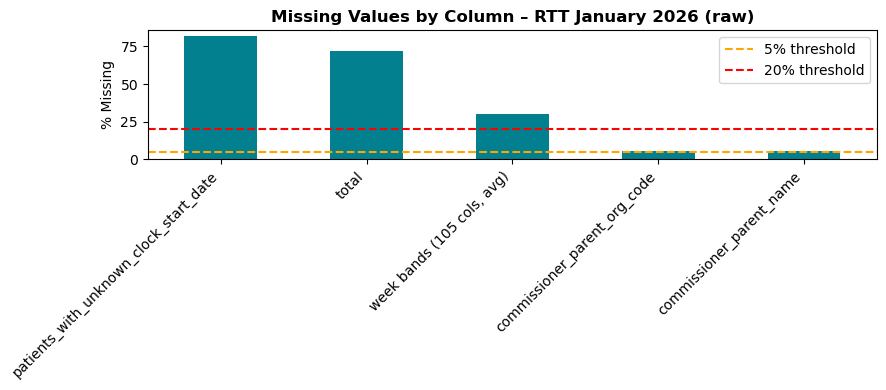

In [89]:
#missing values chart
import matplotlib.pyplot as plt

raw_cols = df_jan26.columns  
missing_pct = (df_jan26.isnull().mean() * 100)

week_cols = [c for c in df_jan26.columns if c.startswith("gt_")]
summary = missing_pct.drop(week_cols)
summary["week bands (105 cols, avg)"] = missing_pct[week_cols].mean()
summary = summary[summary > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
summary.plot(kind="bar", color="#028090", ax=ax)
ax.set_ylabel("% Missing")
ax.set_title("Missing Values by Column – RTT January 2026 (raw)", fontweight="bold")
ax.axhline(5, color="orange", ls="--", label="5% threshold")
ax.axhline(20, color="red", ls="--", label="20% threshold")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("DQ_Missing_Values.png", dpi=150)
plt.show()

In [90]:
#Save January 2026cleaned
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

In [91]:
%who DataFrame

clean	 clean_nov	 df	 df_dec	 df_jan26	 df_nov	 inc	 incomplete_pathway	 raw	 
sep_clean	 


In [92]:
del clean, df_dec, df_jan26, inc, raw

In [93]:
import pandas as pd
import os

In [94]:
#February 2026
raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_feb26 = raw.copy()          
                
print(df_feb26.shape)

(181233, 121)


In [95]:
#check datatypes
print(df_feb26.dtypes)

Period                                     object
Provider Parent Org Code                   object
Provider Parent Name                       object
Provider Org Code                          object
Provider Org Name                          object
Commissioner Parent Org Code               object
Commissioner Parent Name                   object
Commissioner Org Code                      object
Commissioner Org Name                      object
RTT Part Type                              object
RTT Part Description                       object
Treatment Function Code                    object
Treatment Function Name                    object
Gt 00 To 01 Weeks SUM 1                   float64
Gt 01 To 02 Weeks SUM 1                   float64
Gt 02 To 03 Weeks SUM 1                   float64
Gt 03 To 04 Weeks SUM 1                   float64
Gt 04 To 05 Weeks SUM 1                   float64
Gt 05 To 06 Weeks SUM 1                   float64
Gt 06 To 07 Weeks SUM 1                   float64


In [96]:
#Standardise columns
df_feb26.columns = (df_feb26.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_feb26.columns.tolist())

['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [97]:
#fix data types
# "RTT-February-2026" -> real date
df_feb26["period"] = pd.to_datetime(df_feb26["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_feb26.columns if c.startswith("gt_")]
df_feb26[week_cols] = df_feb26[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_feb26.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [98]:
#Strip whitespaces from text values
text_cols = df_feb26.select_dtypes("object").columns
for c in text_cols:
    df_feb26[c] = df_feb26[c].str.strip()

In [99]:
#Investigate missing values
missing = df_feb26.isnull().sum()
print(missing[missing > 0])


# Are the blanks tied to particular pathway types?
print(df_feb26.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10428
commissioner_parent_name                   10428
commissioner_org_name                       3244
gt_00_to_01_weeks_sum_1                    49800
gt_01_to_02_weeks_sum_1                    50157
gt_02_to_03_weeks_sum_1                    50017
gt_03_to_04_weeks_sum_1                    50072
gt_04_to_05_weeks_sum_1                    50308
gt_05_to_06_weeks_sum_1                    50602
gt_06_to_07_weeks_sum_1                    50754
gt_07_to_08_weeks_sum_1                    50859
gt_08_to_09_weeks_sum_1                    51728
gt_09_to_10_weeks_sum_1                    51647
gt_10_to_11_weeks_sum_1                    51015
gt_11_to_12_weeks_sum_1                    51072
gt_12_to_13_weeks_sum_1                    51097
gt_13_to_14_weeks_sum_1                    51228
gt_14_to_15_weeks_sum_1                    51443
gt_15_to_16_weeks_sum_1                    51458
gt_16_to_17_weeks_sum_1                    51572
gt_17_to_18_weeks_su

In [100]:
#Percentage blanks
print((missing[missing > 0] / len(df_feb26) * 100).round(1))
print(df_feb26["rtt_part_type"].value_counts(normalize=True).mul(100).round(1))

commissioner_parent_org_code               5.8
commissioner_parent_name                   5.8
commissioner_org_name                      1.8
gt_00_to_01_weeks_sum_1                   27.5
gt_01_to_02_weeks_sum_1                   27.7
gt_02_to_03_weeks_sum_1                   27.6
gt_03_to_04_weeks_sum_1                   27.6
gt_04_to_05_weeks_sum_1                   27.8
gt_05_to_06_weeks_sum_1                   27.9
gt_06_to_07_weeks_sum_1                   28.0
gt_07_to_08_weeks_sum_1                   28.1
gt_08_to_09_weeks_sum_1                   28.5
gt_09_to_10_weeks_sum_1                   28.5
gt_10_to_11_weeks_sum_1                   28.1
gt_11_to_12_weeks_sum_1                   28.2
gt_12_to_13_weeks_sum_1                   28.2
gt_13_to_14_weeks_sum_1                   28.3
gt_14_to_15_weeks_sum_1                   28.4
gt_15_to_16_weeks_sum_1                   28.4
gt_16_to_17_weeks_sum_1                   28.5
gt_17_to_18_weeks_sum_1                   28.6
gt_18_to_19_w

In [101]:
#blank commissioner names replaced with not-recorded; a structural defect
df_feb26["commissioner_org_name"] = df_feb26["commissioner_org_name"].fillna("Not recorded")

In [102]:
#Remove duplicate rows
duplicate_rows = df_feb26.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_feb26 = df_feb26.drop_duplicates()

Duplicates: 0


In [103]:
#checking ranges...plausible ranges to check for negative patients
neg = (df_feb26[week_cols] < 0).sum().sum()
print("Negative counts:", neg)

Negative counts: 0


In [104]:
#check rows by row for week band
inc = df_feb26[df_feb26["rtt_part_type"] == "Part_2"]
band_sum = inc[week_cols].sum(axis=1)
fail = inc["total_all"].isnull() | ((inc["total_all"] - band_sum).abs() > 0)
print("Failures:", fail.sum(), "of", len(inc))

Failures: 0 of 64559


In [105]:
#Check labels for constistency
print(df_feb26["treatment_function_name"].value_counts())
print(df_feb26["provider_org_name"].nunique(), "trust names |",
         df_feb26["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                40129
Trauma and Orthopaedic Service       15413
Ophthalmology Service                12480
Other - Medical Services              9847
Gynaecology Service                   9200
General Surgery Service               9067
Urology Service                       8990
Ear Nose and Throat Service           8523
Other - Surgical Services             8458
Oral Surgery Service                  7269
Gastroenterology Service              7199
Cardiology Service                    6349
Other - Paediatric Services           5832
Dermatology Service                   4906
Other - Other Services                4881
Plastic Surgery Service               4329
Respiratory Medicine Service          4323
Neurology Service                     3939
Rheumatology Service                  3222
Neurosurgical Service                 2249
General Internal Medicine Service     1633
Elderly Medicine Service              1390
Cardiothoracic Surgery Service

In [106]:
#Trust names and codes inconsistency
#check this and find which
names = df_feb26.groupby("provider_org_name")["provider_org_code"].nunique()
dup_name = names[names > 1]
print(dup_name)

df_feb26[df_feb26["provider_org_name"].isin(dup_name.index)][
    ["provider_org_code", "provider_org_name"]].drop_duplicates()

provider_org_name
DUCHY HOSPITAL    2
Name: provider_org_code, dtype: int64


,provider_org_code,provider_org_name
98007,NT447,DUCHY HOSPITAL
128475,NVC04,DUCHY HOSPITAL


In [107]:
#checking the parents and patient numbers...two different hospitals sharing same name
df_feb26[df_feb26["provider_org_code"].isin(["NT447", "NVC04"])].groupby(
    ["provider_org_code", "provider_parent_name"])["total"].sum()

provider_org_code  provider_parent_name                                      
NT447              NHS HUMBER AND NORTH YORKSHIRE INTEGRATED CARE BOARD          194.0
NVC04              NHS CORNWALL AND THE ISLES OF SCILLY INTEGRATED CARE BOARD    396.0
Name: total, dtype: float64

In [108]:
clean = df_feb26[(df_feb26["rtt_part_type"] == "Part_2") &
           (df_feb26["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(51580, 113)


In [109]:
#confirmation of part 2 as waiting list
print(df_feb26[df_feb26["treatment_function_code"] == "C_999"].groupby("rtt_part_type")["total_all"].sum().apply("{:,.0f}".format))

rtt_part_type
Part_1A      290,744
Part_1B    1,211,716
Part_2     7,156,212
Part_2A    1,189,814
Part_3     1,728,233
Name: total_all, dtype: object


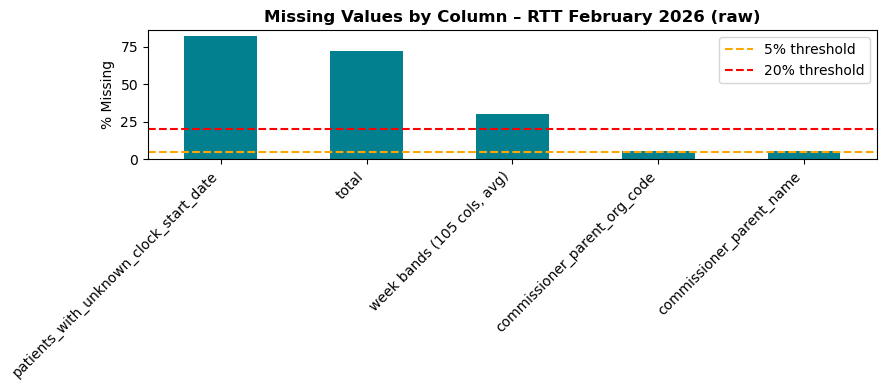

In [110]:
#missing values chart
import matplotlib.pyplot as plt

raw_cols = df_feb26.columns  
missing_pct = (df_feb26.isnull().mean() * 100)

week_cols = [c for c in df_feb26.columns if c.startswith("gt_")]
summary = missing_pct.drop(week_cols)
summary["week bands (105 cols, avg)"] = missing_pct[week_cols].mean()
summary = summary[summary > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
summary.plot(kind="bar", color="#028090", ax=ax)
ax.set_ylabel("% Missing")
ax.set_title("Missing Values by Column – RTT February 2026 (raw)", fontweight="bold")
ax.axhline(5, color="orange", ls="--", label="5% threshold")
ax.axhline(20, color="red", ls="--", label="20% threshold")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("DQ_Missing_Values.png", dpi=150)
plt.show()


In [111]:
#Save February 2026cleaned
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

In [112]:
%who DataFrame

clean	 clean_nov	 df	 df_feb26	 df_nov	 inc	 incomplete_pathway	 raw	 sep_clean	 



In [113]:
del clean, df_feb26, inc, raw

In [114]:
%who DataFrame

clean_nov	 df	 df_nov	 incomplete_pathway	 sep_clean	 


In [115]:
#March
raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_mar26 = raw.copy()          
                
print(df_mar26.shape)

(184184, 121)


In [116]:
#check datatypes
print(df_mar26.dtypes)

Period                                     object
Provider Parent Org Code                   object
Provider Parent Name                       object
Provider Org Code                          object
Provider Org Name                          object
Commissioner Parent Org Code               object
Commissioner Parent Name                   object
Commissioner Org Code                      object
Commissioner Org Name                      object
RTT Part Type                              object
RTT Part Description                       object
Treatment Function Code                    object
Treatment Function Name                    object
Gt 00 To 01 Weeks SUM 1                   float64
Gt 01 To 02 Weeks SUM 1                   float64
Gt 02 To 03 Weeks SUM 1                   float64
Gt 03 To 04 Weeks SUM 1                   float64
Gt 04 To 05 Weeks SUM 1                   float64
Gt 05 To 06 Weeks SUM 1                   float64
Gt 06 To 07 Weeks SUM 1                   float64


In [117]:
#Standardise columns
df_mar26.columns = (df_mar26.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_mar26.columns.tolist())

['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [118]:
#fix data types
# "RTT-march-2026" -> real date
df_mar26["period"] = pd.to_datetime(df_mar26["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_mar26.columns if c.startswith("gt_")]
df_mar26[week_cols] = df_mar26[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_mar26.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [119]:
#Strip whitespaces from text values
text_cols = df_mar26.select_dtypes("object").columns
for c in text_cols:
    df_mar26[c] = df_mar26[c].str.strip()

In [120]:
#Investigate missing values
missing = df_mar26.isnull().sum()
print(missing[missing > 0])


# Are the blanks tied to particular pathway types?
print(df_mar26.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10596
commissioner_parent_name                   10596
commissioner_org_name                       3383
gt_00_to_01_weeks_sum_1                    50876
gt_01_to_02_weeks_sum_1                    51780
gt_02_to_03_weeks_sum_1                    51837
gt_03_to_04_weeks_sum_1                    51914
gt_04_to_05_weeks_sum_1                    51921
gt_05_to_06_weeks_sum_1                    52163
gt_06_to_07_weeks_sum_1                    52232
gt_07_to_08_weeks_sum_1                    52396
gt_08_to_09_weeks_sum_1                    52438
gt_09_to_10_weeks_sum_1                    52769
gt_10_to_11_weeks_sum_1                    52927
gt_11_to_12_weeks_sum_1                    53000
gt_12_to_13_weeks_sum_1                    53571
gt_13_to_14_weeks_sum_1                    53909
gt_14_to_15_weeks_sum_1                    53159
gt_15_to_16_weeks_sum_1                    53140
gt_16_to_17_weeks_sum_1                    53268
gt_17_to_18_weeks_su

In [121]:
#blank commissioner names replaced with not-recorded; a structural defect
df_mar26["commissioner_org_name"] = df_mar26["commissioner_org_name"].fillna("Not recorded")

In [122]:
#Remove duplicate rows
duplicate_rows = df_mar26.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_mar26 = df_mar26.drop_duplicates()

Duplicates: 0


In [123]:
#checking ranges...plausible ranges to check for negative patients
neg = (df_mar26[week_cols] < 0).sum().sum()
print("Negative counts:", neg)

Negative counts: 0


In [124]:
#check rows by row for week band
inc = df_mar26[df_mar26["rtt_part_type"] == "Part_2"]
band_sum = inc[week_cols].sum(axis=1)
fail = inc["total_all"].isnull() | ((inc["total_all"] - band_sum).abs() > 0)
print("Failures:", fail.sum(), "of", len(inc))

Failures: 0 of 63833


In [125]:
#Check labels for constistency
print(df_mar26["treatment_function_name"].value_counts())
print(df_mar26["provider_org_name"].nunique(), "trust names |",
         df_mar26["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                40842
Trauma and Orthopaedic Service       15498
Ophthalmology Service                12807
Other - Medical Services             10076
Gynaecology Service                   9379
General Surgery Service               9148
Urology Service                       9077
Ear Nose and Throat Service           8768
Other - Surgical Services             8638
Oral Surgery Service                  7433
Gastroenterology Service              7207
Cardiology Service                    6457
Other - Paediatric Services           5956
Other - Other Services                5029
Dermatology Service                   4868
Respiratory Medicine Service          4380
Plastic Surgery Service               4358
Neurology Service                     3991
Rheumatology Service                  3274
Neurosurgical Service                 2256
General Internal Medicine Service     1653
Elderly Medicine Service              1434
Cardiothoracic Surgery Service

In [126]:
#Trust names and codes inconsistency
#check this and find which
names = df_mar26.groupby("provider_org_name")["provider_org_code"].nunique()
dup_name = names[names > 1]
print(dup_name)

df_mar26[df_mar26["provider_org_name"].isin(dup_name.index)][
    ["provider_org_code", "provider_org_name"]].drop_duplicates()

provider_org_name
DUCHY HOSPITAL    2
Name: provider_org_code, dtype: int64


,provider_org_code,provider_org_name
100284,NT447,DUCHY HOSPITAL
131051,NVC04,DUCHY HOSPITAL


In [127]:
#checking the parents and patient numbers...two different hospitals sharing same name
df_mar26[df_mar26["provider_org_code"].isin(["NT447", "NVC04"])].groupby(
    ["provider_org_code", "provider_parent_name"])["total"].sum()

provider_org_code  provider_parent_name                                      
NT447              NHS HUMBER AND NORTH YORKSHIRE INTEGRATED CARE BOARD          230.0
NVC04              NHS CORNWALL AND THE ISLES OF SCILLY INTEGRATED CARE BOARD    506.0
Name: total, dtype: float64

In [128]:
clean = df_mar26[(df_mar26["rtt_part_type"] == "Part_2") &
           (df_mar26["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(50900, 113)


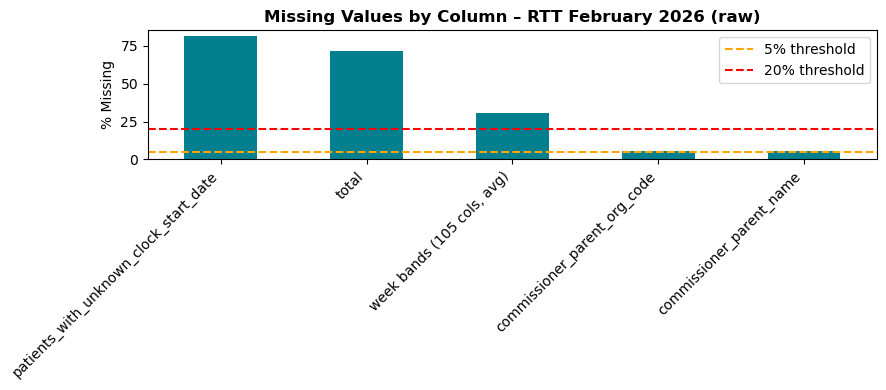

In [129]:
#missing values chart
import matplotlib.pyplot as plt

raw_cols = df_mar26.columns  
missing_pct = (df_mar26.isnull().mean() * 100)

week_cols = [c for c in df_mar26.columns if c.startswith("gt_")]
summary = missing_pct.drop(week_cols)
summary["week bands (105 cols, avg)"] = missing_pct[week_cols].mean()
summary = summary[summary > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
summary.plot(kind="bar", color="#028090", ax=ax)
ax.set_ylabel("% Missing")
ax.set_title("Missing Values by Column – RTT February 2026 (raw)", fontweight="bold")
ax.axhline(5, color="orange", ls="--", label="5% threshold")
ax.axhline(20, color="red", ls="--", label="20% threshold")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("DQ_Missing_Values.png", dpi=150)
plt.show()


In [130]:
#Save March 2026cleaned
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

In [131]:
%who DataFrame

clean	 clean_nov	 df	 df_mar26	 df_nov	 inc	 incomplete_pathway	 raw	 sep_clean	 



In [132]:
del clean,df_mar26, inc, raw

In [133]:
#April
raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_apr26 = raw.copy()          
                
print(df_apr26.shape)

(180781, 121)


In [134]:
print(df_apr26.dtypes)

Period                                     object
Provider Parent Org Code                   object
Provider Parent Name                       object
Provider Org Code                          object
Provider Org Name                          object
Commissioner Parent Org Code               object
Commissioner Parent Name                   object
Commissioner Org Code                      object
Commissioner Org Name                      object
RTT Part Type                              object
RTT Part Description                       object
Treatment Function Code                    object
Treatment Function Name                    object
Gt 00 To 01 Weeks SUM 1                   float64
Gt 01 To 02 Weeks SUM 1                   float64
Gt 02 To 03 Weeks SUM 1                   float64
Gt 03 To 04 Weeks SUM 1                   float64
Gt 04 To 05 Weeks SUM 1                   float64
Gt 05 To 06 Weeks SUM 1                   float64
Gt 06 To 07 Weeks SUM 1                   float64


In [135]:
#Standardise columns
df_apr26.columns = (df_apr26.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_apr26.columns.tolist())

['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [136]:
#fix data types
# "RTT-April-2026" -> real date
df_apr26["period"] = pd.to_datetime(df_apr26["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_apr26.columns if c.startswith("gt_")]
df_apr26[week_cols] = df_apr26[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_apr26.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [137]:
#Strip whitespaces from text values
text_cols = df_apr26.select_dtypes("object").columns
for c in text_cols:
    df_apr26[c] = df_apr26[c].str.strip()

In [138]:
#Investigate missing values
missing = df_apr26.isnull().sum()
print(missing[missing > 0])


# Are the blanks tied to particular pathway types?
print(df_apr26.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10266
commissioner_parent_name                   10266
commissioner_org_name                       3289
gt_00_to_01_weeks_sum_1                    49709
gt_01_to_02_weeks_sum_1                    50567
gt_02_to_03_weeks_sum_1                    50592
gt_03_to_04_weeks_sum_1                    51221
gt_04_to_05_weeks_sum_1                    50711
gt_05_to_06_weeks_sum_1                    50877
gt_06_to_07_weeks_sum_1                    50986
gt_07_to_08_weeks_sum_1                    51047
gt_08_to_09_weeks_sum_1                    51172
gt_09_to_10_weeks_sum_1                    51392
gt_10_to_11_weeks_sum_1                    51473
gt_11_to_12_weeks_sum_1                    51470
gt_12_to_13_weeks_sum_1                    51576
gt_13_to_14_weeks_sum_1                    51684
gt_14_to_15_weeks_sum_1                    51907
gt_15_to_16_weeks_sum_1                    52072
gt_16_to_17_weeks_sum_1                    52449
gt_17_to_18_weeks_su

In [139]:
#blank commissioner names replaced with not-recorded; a structural defect
df_apr26["commissioner_org_name"] = df_apr26["commissioner_org_name"].fillna("Not recorded")

In [140]:
#Remove duplicate rows
duplicate_rows = df_apr26.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_apr26 = df_apr26.drop_duplicates()

Duplicates: 0


In [141]:
#checking ranges...plausible ranges to check for negative patients
neg = (df_apr26[week_cols] < 0).sum().sum()
print("Negative counts:", neg)

Negative counts: 0


In [142]:
#check rows by row for week band
inc = df_apr26[df_apr26["rtt_part_type"] == "Part_2"]
band_sum = inc[week_cols].sum(axis=1)
fail = inc["total_all"].isnull() | ((inc["total_all"] - band_sum).abs() > 0)
print("Failures:", fail.sum(), "of", len(inc))

Failures: 0 of 63654


In [143]:
#Check labels for constistency
print(df_apr26["treatment_function_name"].value_counts())
print(df_apr26["provider_org_name"].nunique(), "trust names |",
         df_apr26["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                40102
Trauma and Orthopaedic Service       15347
Ophthalmology Service                12685
Other - Medical Services              9684
Gynaecology Service                   9149
General Surgery Service               9144
Urology Service                       8933
Ear Nose and Throat Service           8540
Other - Surgical Services             8348
Oral Surgery Service                  7315
Gastroenterology Service              7032
Cardiology Service                    6333
Other - Paediatric Services           5835
Other - Other Services                4921
Dermatology Service                   4789
Respiratory Medicine Service          4350
Plastic Surgery Service               4323
Neurology Service                     3840
Rheumatology Service                  3187
Neurosurgical Service                 2306
General Internal Medicine Service     1645
Elderly Medicine Service              1356
Cardiothoracic Surgery Service

In [144]:
#Trust names and codes inconsistency
#check this and find which
names = df_apr26.groupby("provider_org_name")["provider_org_code"].nunique()
dup_name = names[names > 1]
print(dup_name)

df_apr26[df_apr26["provider_org_name"].isin(dup_name.index)][
    ["provider_org_code", "provider_org_name"]].drop_duplicates()

provider_org_name
DUCHY HOSPITAL    2
Name: provider_org_code, dtype: int64


,provider_org_code,provider_org_name
76397,NT447,DUCHY HOSPITAL
96718,NVC04,DUCHY HOSPITAL


In [145]:
#checking the parents and patient numbers...two different hospitals sharing same name
df_apr26[df_apr26["provider_org_code"].isin(["NT447", "NVC04"])].groupby(
    ["provider_org_code", "provider_parent_name"])["total"].sum()

provider_org_code  provider_parent_name                                      
NT447              NHS HUMBER AND NORTH YORKSHIRE INTEGRATED CARE BOARD          152.0
NVC04              NHS CORNWALL AND THE ISLES OF SCILLY INTEGRATED CARE BOARD    434.0
Name: total, dtype: float64

In [146]:
clean = df_apr26[(df_apr26["rtt_part_type"] == "Part_2") &
           (df_apr26["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(50785, 113)


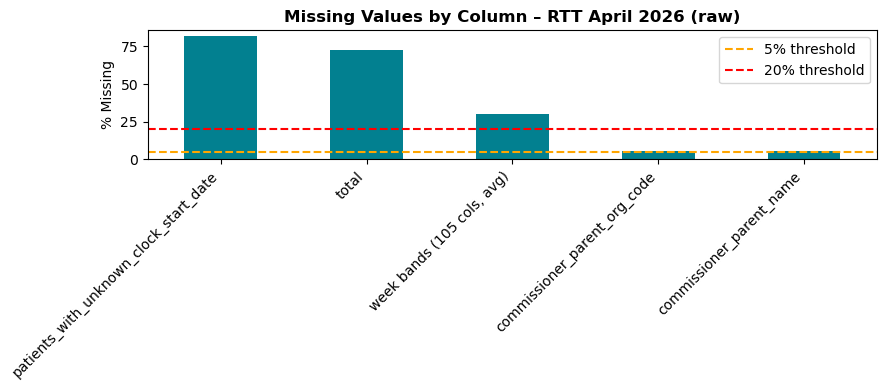

In [147]:
#missing values chart
import matplotlib.pyplot as plt

raw_cols = df_apr26.columns  
missing_pct = (df_apr26.isnull().mean() * 100)

week_cols = [c for c in df_apr26.columns if c.startswith("gt_")]
summary = missing_pct.drop(week_cols)
summary["week bands (105 cols, avg)"] = missing_pct[week_cols].mean()
summary = summary[summary > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
summary.plot(kind="bar", color="#028090", ax=ax)
ax.set_ylabel("% Missing")
ax.set_title("Missing Values by Column – RTT April 2026 (raw)", fontweight="bold")
ax.axhline(5, color="orange", ls="--", label="5% threshold")
ax.axhline(20, color="red", ls="--", label="20% threshold")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("DQ_Missing_Values.png", dpi=150)
plt.show()


In [148]:
#Save April 2026cleaned
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

In [149]:
import pandas as pd
import os
#May

raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_may26 = raw.copy()          
                
print(df_may26.shape)

(178171, 121)


In [150]:
print(df_may26.dtypes)

Period                                     object
Provider Parent Org Code                   object
Provider Parent Name                       object
Provider Org Code                          object
Provider Org Name                          object
Commissioner Parent Org Code               object
Commissioner Parent Name                   object
Commissioner Org Code                      object
Commissioner Org Name                      object
RTT Part Type                              object
RTT Part Description                       object
Treatment Function Code                    object
Treatment Function Name                    object
Gt 00 To 01 Weeks SUM 1                   float64
Gt 01 To 02 Weeks SUM 1                   float64
Gt 02 To 03 Weeks SUM 1                   float64
Gt 03 To 04 Weeks SUM 1                   float64
Gt 04 To 05 Weeks SUM 1                   float64
Gt 05 To 06 Weeks SUM 1                   float64
Gt 06 To 07 Weeks SUM 1                   float64


In [151]:
#Standardise columns
df_may26.columns = (df_may26.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_may26.columns.tolist())

['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [152]:
print(df_may26[week_cols].dtypes.value_counts())
print(df_may26["gt_00_to_01_weeks_sum_1"].head(10))

float64    105
Name: count, dtype: int64
0    0.0
1    0.0
2    0.0
3    0.0
4    2.0
5    2.0
6    1.0
7    1.0
8    NaN
9    NaN
Name: gt_00_to_01_weeks_sum_1, dtype: float64


In [153]:
#fix data types
# "RTT-May-2026" -> real date
df_may26["period"] = pd.to_datetime(df_may26["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_may26.columns if c.startswith("gt_")]
df_may26[week_cols] = df_may26[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_may26.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [154]:
#Strip whitespaces from text values
text_cols = df_may26.select_dtypes("object").columns
for c in text_cols:
    df_may26[c] = df_may26[c].str.strip()

In [155]:
#Investigate missing values
missing = df_may26.isnull().sum()
print(missing[missing > 0])


# Are the blanks tied to particular pathway types?
print(df_may26.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10007
commissioner_parent_name                   10007
commissioner_org_name                       3241
gt_00_to_01_weeks_sum_1                    49903
gt_01_to_02_weeks_sum_1                    49954
gt_02_to_03_weeks_sum_1                    49968
gt_03_to_04_weeks_sum_1                    50322
gt_04_to_05_weeks_sum_1                    50076
gt_05_to_06_weeks_sum_1                    50381
gt_06_to_07_weeks_sum_1                    50479
gt_07_to_08_weeks_sum_1                    51021
gt_08_to_09_weeks_sum_1                    50975
gt_09_to_10_weeks_sum_1                    50893
gt_10_to_11_weeks_sum_1                    50952
gt_11_to_12_weeks_sum_1                    51100
gt_12_to_13_weeks_sum_1                    51188
gt_13_to_14_weeks_sum_1                    51237
gt_14_to_15_weeks_sum_1                    51539
gt_15_to_16_weeks_sum_1                    51428
gt_16_to_17_weeks_sum_1                    51492
gt_17_to_18_weeks_su

In [156]:
#blank commissioner names replaced with not-recorded; a structural defect
df_may26["commissioner_org_name"] = df_may26["commissioner_org_name"].fillna("Not recorded")

In [157]:
#Remove duplicate rows
duplicate_rows = df_may26.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_may26 = df_may26.drop_duplicates()

Duplicates: 0


In [158]:
#checking ranges...plausible ranges to check for negative patients
neg = (df_may26[week_cols] < 0).sum().sum()
print("Negative counts:", neg)

Negative counts: 0


In [159]:
#check rows by row for week band
inc = df_may26[df_may26["rtt_part_type"] == "Part_2"]
band_sum = inc[week_cols].sum(axis=1)
fail = inc["total_all"].isnull() | ((inc["total_all"] - band_sum).abs() > 0)
print("Failures:", fail.sum(), "of", len(inc))

Failures: 0 of 63321


In [160]:
#Check labels for constistency
print(df_may26["treatment_function_name"].value_counts())
print(df_may26["provider_org_name"].nunique(), "trust names |",
         df_may26["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                39677
Trauma and Orthopaedic Service       15237
Ophthalmology Service                12623
Other - Medical Services              9438
Gynaecology Service                   9221
General Surgery Service               9001
Urology Service                       8843
Ear Nose and Throat Service           8532
Other - Surgical Services             8296
Oral Surgery Service                  7019
Gastroenterology Service              6853
Cardiology Service                    6145
Other - Paediatric Services           5725
Other - Other Services                4858
Dermatology Service                   4564
Respiratory Medicine Service          4255
Plastic Surgery Service               4214
Neurology Service                     3740
Rheumatology Service                  3172
Neurosurgical Service                 2189
General Internal Medicine Service     1620
Elderly Medicine Service              1377
Cardiothoracic Surgery Service

In [161]:
#Trust names and codes inconsistency
#check this and find which
names = df_may26.groupby("provider_org_name")["provider_org_code"].nunique()
dup_name = names[names > 1]
print(dup_name)

df_may26[df_may26["provider_org_name"].isin(dup_name.index)][
    ["provider_org_code", "provider_org_name"]].drop_duplicates()

provider_org_name
DUCHY HOSPITAL    2
Name: provider_org_code, dtype: int64


,provider_org_code,provider_org_name
76155,NT447,DUCHY HOSPITAL
96229,NVC04,DUCHY HOSPITAL


In [162]:
#checking the parents and patient numbers...two different hospitals sharing same name
df_may26[df_may26["provider_org_code"].isin(["NT447", "NVC04"])].groupby(
    ["provider_org_code", "provider_parent_name"])["total"].sum()

provider_org_code  provider_parent_name                                      
NT447              NHS HUMBER AND NORTH YORKSHIRE INTEGRATED CARE BOARD          184.0
NVC04              NHS CORNWALL AND THE ISLES OF SCILLY INTEGRATED CARE BOARD    462.0
Name: total, dtype: float64

In [163]:
clean = df_may26[(df_may26["rtt_part_type"] == "Part_2") &
           (df_may26["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(50436, 113)


In [164]:
print(clean["period"].unique())
print(f"{clean[week_cols].sum().sum():,.0f}  vs  {clean['total_all'].sum():,.0f}")

<DatetimeArray>
['2026-05-01 00:00:00']
Length: 1, dtype: datetime64[ns]
7,184,233  vs  7,184,233


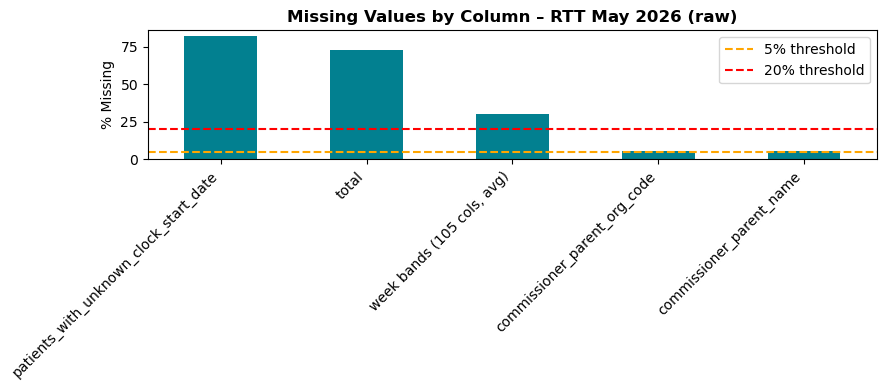

In [165]:
#missing values chart
import matplotlib.pyplot as plt

raw_cols = df_may26.columns  
missing_pct = (df_may26.isnull().mean() * 100)

week_cols = [c for c in df_may26.columns if c.startswith("gt_")]
summary = missing_pct.drop(week_cols)
summary["week bands (105 cols, avg)"] = missing_pct[week_cols].mean()
summary = summary[summary > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
summary.plot(kind="bar", color="#028090", ax=ax)
ax.set_ylabel("% Missing")
ax.set_title("Missing Values by Column – RTT May 2026 (raw)", fontweight="bold")
ax.axhline(5, color="orange", ls="--", label="5% threshold")
ax.axhline(20, color="red", ls="--", label="20% threshold")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("DQ_Missing_Values.png", dpi=150)
plt.show()


In [166]:
#Save May 2026cleaned
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

In [167]:
#june
raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_jun26 = raw.copy()          
                
print(df_jun26.shape)

(182411, 121)


In [168]:
print(df_jun26.dtypes)

Period                                     object
Provider Parent Org Code                   object
Provider Parent Name                       object
Provider Org Code                          object
Provider Org Name                          object
Commissioner Parent Org Code               object
Commissioner Parent Name                   object
Commissioner Org Code                      object
Commissioner Org Name                      object
RTT Part Type                              object
RTT Part Description                       object
Treatment Function Code                    object
Treatment Function Name                    object
Gt 00 To 01 Weeks SUM 1                   float64
Gt 01 To 02 Weeks SUM 1                   float64
Gt 02 To 03 Weeks SUM 1                   float64
Gt 03 To 04 Weeks SUM 1                   float64
Gt 04 To 05 Weeks SUM 1                   float64
Gt 05 To 06 Weeks SUM 1                   float64
Gt 06 To 07 Weeks SUM 1                   float64


In [169]:
#Standardise columns
df_jun26.columns = (df_jun26.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_jun26.columns.tolist())

['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [170]:
#fix data types
# "RTT-june-2026" -> real date
df_jun26["period"] = pd.to_datetime(df_jun26["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_jun26.columns if c.startswith("gt_")]
df_jun26[week_cols] = df_jun26[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_jun26.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [171]:
#Strip whitespaces from text values
text_cols = df_jun26.select_dtypes("object").columns
for c in text_cols:
    df_jun26[c] = df_jun26[c].str.strip()

In [172]:
#Investigate missing values
missing = df_jun26.isnull().sum()
print(missing[missing > 0])


# Are the blanks tied to particular pathway types?
print(df_jun26.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10263
commissioner_parent_name                   10263
commissioner_org_name                       3348
gt_00_to_01_weeks_sum_1                    50850
gt_01_to_02_weeks_sum_1                    51715
gt_02_to_03_weeks_sum_1                    51813
gt_03_to_04_weeks_sum_1                    51842
gt_04_to_05_weeks_sum_1                    52061
gt_05_to_06_weeks_sum_1                    52251
gt_06_to_07_weeks_sum_1                    52095
gt_07_to_08_weeks_sum_1                    52258
gt_08_to_09_weeks_sum_1                    52656
gt_09_to_10_weeks_sum_1                    52611
gt_10_to_11_weeks_sum_1                    52780
gt_11_to_12_weeks_sum_1                    52909
gt_12_to_13_weeks_sum_1                    53358
gt_13_to_14_weeks_sum_1                    52987
gt_14_to_15_weeks_sum_1                    53107
gt_15_to_16_weeks_sum_1                    53161
gt_16_to_17_weeks_sum_1                    53284
gt_17_to_18_weeks_su

In [173]:
#blank commissioner names replaced with not-recorded; a structural defect
df_jun26["commissioner_org_name"] = df_jun26["commissioner_org_name"].fillna("Not recorded")

In [174]:
#Remove duplicate rows
duplicate_rows = df_jun26.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_jun26 = df_jun26.drop_duplicates()

Duplicates: 0


In [175]:
#checking ranges...plausible ranges to check for negative patients
neg = (df_jun26[week_cols] < 0).sum().sum()
print("Negative counts:", neg)

Negative counts: 0


In [176]:
#Check labels for constistency
print(df_jun26["treatment_function_name"].value_counts())
print(df_jun26["provider_org_name"].nunique(), "trust names |",
         df_jun26["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                40636
Trauma and Orthopaedic Service       15507
Ophthalmology Service                13028
Other - Medical Services              9736
Gynaecology Service                   9243
General Surgery Service               9149
Urology Service                       9047
Other - Surgical Services             8716
Ear Nose and Throat Service           8673
Oral Surgery Service                  7219
Gastroenterology Service              6986
Cardiology Service                    6294
Other - Paediatric Services           5808
Other - Other Services                5005
Dermatology Service                   4777
Respiratory Medicine Service          4345
Plastic Surgery Service               4279
Neurology Service                     3867
Rheumatology Service                  3254
Neurosurgical Service                 2218
General Internal Medicine Service     1596
Elderly Medicine Service              1388
Cardiothoracic Surgery Service

In [177]:
clean = df_jun26[(df_jun26["rtt_part_type"] == "Part_2") &
           (df_jun26["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(50419, 113)


In [178]:
#Save june 2026cleaned
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

In [179]:
#July

raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_jul26 = raw.copy()          
                
print(df_jul26.shape)

(182372, 121)


In [180]:
print(df_jul26.dtypes)

Period                                     object
Provider Parent Org Code                   object
Provider Parent Name                       object
Provider Org Code                          object
Provider Org Name                          object
Commissioner Parent Org Code               object
Commissioner Parent Name                   object
Commissioner Org Code                      object
Commissioner Org Name                      object
RTT Part Type                              object
RTT Part Description                       object
Treatment Function Code                    object
Treatment Function Name                    object
Gt 00 To 01 Weeks SUM 1                   float64
Gt 01 To 02 Weeks SUM 1                   float64
Gt 02 To 03 Weeks SUM 1                   float64
Gt 03 To 04 Weeks SUM 1                   float64
Gt 04 To 05 Weeks SUM 1                   float64
Gt 05 To 06 Weeks SUM 1                   float64
Gt 06 To 07 Weeks SUM 1                   float64


In [181]:
#Standardise columns
df_jul26.columns = (df_jul26.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_jul26.columns.tolist())

['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [182]:
#fix data types
# "RTT-july-2026" -> real date
df_jul26["period"] = pd.to_datetime(df_jul26["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_jul26.columns if c.startswith("gt_")]
df_jul26[week_cols] = df_jul26[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_jul26.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [183]:
#Strip whitespaces from text values
text_cols = df_jul26.select_dtypes("object").columns
for c in text_cols:
    df_jul26[c] = df_jul26[c].str.strip()

In [184]:
#Investigate missing values
missing = df_jul26.isnull().sum()
print(missing[missing > 0])


# Are the blanks tied to particular pathway types?
print(df_jul26.groupby("rtt_part_type")[week_cols].apply(lambda x: x.isnull().mean().mean()*100).round(1))

commissioner_parent_org_code               10197
commissioner_parent_name                   10197
commissioner_org_name                       3393
gt_00_to_01_weeks_sum_1                    51418
gt_01_to_02_weeks_sum_1                    52232
gt_02_to_03_weeks_sum_1                    52305
gt_03_to_04_weeks_sum_1                    52363
gt_04_to_05_weeks_sum_1                    52435
gt_05_to_06_weeks_sum_1                    52557
gt_06_to_07_weeks_sum_1                    52746
gt_07_to_08_weeks_sum_1                    52862
gt_08_to_09_weeks_sum_1                    52940
gt_09_to_10_weeks_sum_1                    53438
gt_10_to_11_weeks_sum_1                    53182
gt_11_to_12_weeks_sum_1                    53281
gt_12_to_13_weeks_sum_1                    53525
gt_13_to_14_weeks_sum_1                    53449
gt_14_to_15_weeks_sum_1                    53599
gt_15_to_16_weeks_sum_1                    53691
gt_16_to_17_weeks_sum_1                    54251
gt_17_to_18_weeks_su

In [185]:
#blank commissioner names replaced with not-recorded; a structural defect
df_jul26["commissioner_org_name"] = df_jul26["commissioner_org_name"].fillna("Not recorded")

In [186]:
#Remove duplicate rows
duplicate_rows = df_jul26.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_jul26 = df_jul26.drop_duplicates()

Duplicates: 0


In [187]:
#Check labels for constistency
print(df_jul26["treatment_function_name"].value_counts())
print(df_jul26["provider_org_name"].nunique(), "trust names |",
         df_jul26["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                40627
Trauma and Orthopaedic Service       15512
Ophthalmology Service                13042
Other - Medical Services              9743
Gynaecology Service                   9348
General Surgery Service               9268
Urology Service                       9120
Ear Nose and Throat Service           8627
Other - Surgical Services             8569
Oral Surgery Service                  7117
Gastroenterology Service              7034
Cardiology Service                    6188
Other - Paediatric Services           5880
Other - Other Services                5000
Dermatology Service                   4755
Respiratory Medicine Service          4378
Plastic Surgery Service               4224
Neurology Service                     3831
Rheumatology Service                  3288
Neurosurgical Service                 2147
General Internal Medicine Service     1635
Elderly Medicine Service              1381
Cardiothoracic Surgery Service

In [188]:
clean = df_jul26[(df_jul26["rtt_part_type"] == "Part_2") &
           (df_jul26["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(50368, 113)


In [189]:
#Save july 2026cleaned
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)

In [190]:
#August

raw = pd.read_csv("../data/rtt_combined_sep25_aug26.csv",
                  low_memory=False)
df_aug26 = raw.copy()          
                
print(df_aug26.shape)

(177770, 121)


In [191]:
#Standardise columns
df_aug26.columns = (df_aug26.columns.str.strip().str.lower()
                .str.replace(" ", "_")
                .str.replace(r"[^a-z0-9_]", "", regex=True))
print(df_aug26.columns.tolist())

['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'rtt_part_type', 'rtt_part_description', 'treatment_function_code', 'treatment_function_name', 'gt_00_to_01_weeks_sum_1', 'gt_01_to_02_weeks_sum_1', 'gt_02_to_03_weeks_sum_1', 'gt_03_to_04_weeks_sum_1', 'gt_04_to_05_weeks_sum_1', 'gt_05_to_06_weeks_sum_1', 'gt_06_to_07_weeks_sum_1', 'gt_07_to_08_weeks_sum_1', 'gt_08_to_09_weeks_sum_1', 'gt_09_to_10_weeks_sum_1', 'gt_10_to_11_weeks_sum_1', 'gt_11_to_12_weeks_sum_1', 'gt_12_to_13_weeks_sum_1', 'gt_13_to_14_weeks_sum_1', 'gt_14_to_15_weeks_sum_1', 'gt_15_to_16_weeks_sum_1', 'gt_16_to_17_weeks_sum_1', 'gt_17_to_18_weeks_sum_1', 'gt_18_to_19_weeks_sum_1', 'gt_19_to_20_weeks_sum_1', 'gt_20_to_21_weeks_sum_1', 'gt_21_to_22_weeks_sum_1', 'gt_22_to_23_weeks_sum_1', 'gt_23_to_24_weeks_sum_1', 'gt_24_to_25_weeks_sum_1', 'gt_25_to_26_we

In [192]:
#fix data types
# "RTT-aug-2026" -> real date
df_aug26["period"] = pd.to_datetime(df_aug26["period"].str.replace("RTT-", ""), format="%B-%Y")

# Week bands must be numeric
week_cols = [c for c in df_aug26.columns if c.startswith("gt_")]
df_aug26[week_cols] = df_aug26[week_cols].apply(pd.to_numeric, errors="coerce")
print(df_aug26.dtypes)

period                                    datetime64[ns]
provider_parent_org_code                          object
provider_parent_name                              object
provider_org_code                                 object
provider_org_name                                 object
commissioner_parent_org_code                      object
commissioner_parent_name                          object
commissioner_org_code                             object
commissioner_org_name                             object
rtt_part_type                                     object
rtt_part_description                              object
treatment_function_code                           object
treatment_function_name                           object
gt_00_to_01_weeks_sum_1                          float64
gt_01_to_02_weeks_sum_1                          float64
gt_02_to_03_weeks_sum_1                          float64
gt_03_to_04_weeks_sum_1                          float64
gt_04_to_05_weeks_sum_1        

In [193]:
#Strip whitespaces from text values
text_cols = df_aug26.select_dtypes("object").columns
for c in text_cols:
    df_aug26[c] = df_aug26[c].str.strip()

In [194]:
#blank commissioner names replaced with not-recorded; a structural defect
df_aug26["commissioner_org_name"] = df_aug26["commissioner_org_name"].fillna("Not recorded")

In [195]:
#Remove duplicate rows
duplicate_rows = df_aug26.duplicated().sum()
print("Duplicates:", duplicate_rows)
df_aug26 = df_aug26.drop_duplicates()

Duplicates: 0


In [196]:
#Check labels for constistency
print(df_aug26["treatment_function_name"].value_counts())
print(df_aug26["provider_org_name"].nunique(), "trust names |",
         df_aug26["provider_org_code"].nunique(), "trust codes")

treatment_function_name
Total                                39687
Trauma and Orthopaedic Service       15194
Ophthalmology Service                12744
Other - Medical Services              9442
Gynaecology Service                   9077
Urology Service                       9020
General Surgery Service               8995
Other - Surgical Services             8448
Ear Nose and Throat Service           8367
Oral Surgery Service                  6924
Gastroenterology Service              6808
Cardiology Service                    6008
Other - Paediatric Services           5717
Other - Other Services                4864
Dermatology Service                   4622
Respiratory Medicine Service          4294
Plastic Surgery Service               4156
Neurology Service                     3685
Rheumatology Service                  3182
Neurosurgical Service                 2084
General Internal Medicine Service     1463
Elderly Medicine Service              1359
Cardiothoracic Surgery Service

In [197]:
clean = df_aug26[(df_aug26["rtt_part_type"] == "Part_2") &
           (df_aug26["treatment_function_code"] != "C_999")].copy()

clean[week_cols] = clean[week_cols].fillna(0)

keep = ["period", "provider_org_code", "provider_org_name",
        "commissioner_org_code", "commissioner_org_name",
        "treatment_function_code", "treatment_function_name",
        "total_all"] + week_cols
clean = clean[keep]
print(clean.shape)

(50549, 113)


In [198]:
#Save august 2026cleaned
clean.to_csv("../data/rtt_combined_sep25_aug26.csv",index=False)